# 01 · Data and EDA
Scope: individual 36-month Lending Club loans with a resolved outcome. Train = 2013–14 issues, out-of-time (OOT) = 2015 issues.

In [1]:
import json, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
R = '../reports/'; F = R + 'figures/'
res = json.load(open(R + 'results.json'))

## Why 2013–2015? Outcome counts by issue year (36-month loans)
2016+ loans were still mostly unresolved at the data cut-off (Dec 2018), and the resolved ones are biased towards early defaults.

In [2]:
pd.read_csv(R + 'status_by_year_36m.csv')

,issue_year,total,resolved,resolved_share,bad_rate_resolved
0,2007,603,603,1.000000,0.262023
1,2008,2393,2393,1.000000,0.207271
2,2009,5281,5281,1.000000,0.136906
3,2010,9156,9156,1.000000,0.109218
4,2011,14101,14101,1.000000,0.106305
5,2012,43470,43470,1.000000,0.135795
6,2013,100422,100422,1.000000,0.123260
7,2014,162570,162570,1.000000,0.137264
8,2015,283173,282853,0.998870,0.148657
9,2016,323495,215553,0.666326,0.209146


In [3]:
pd.Series({k: v for k, v in res['data'].items() if not k.startswith('bad_rate_by')}, dtype=object)

n_loans                 545607
bad_rate                0.1406
train_years       [2013, 2014]
oot_years               [2015]
n_train                 262992
n_oot                   282615
bad_rate_train          0.1319
bad_rate_oot            0.1486
dtype: object

,issue_year,n,bads,bad_rate
0,2013,100422,12378,0.123260
1,2014,162570,22315,0.137264
2,2015,282615,42006,0.148633


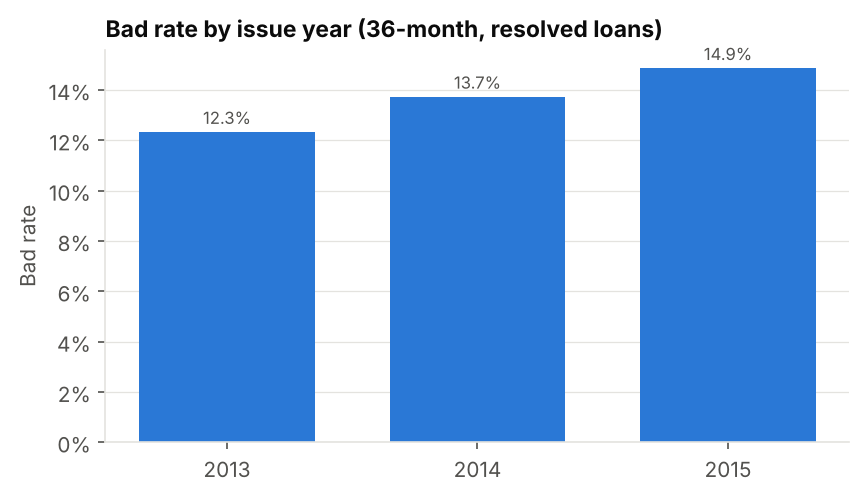

In [4]:
display(pd.read_csv(R + 'bad_rate_by_year.csv')); display(Image(F + 'bad_rate_by_year.png'))

,grade,n,bads,bad_rate
0,A,122471,6475,0.052870
1,B,185361,20548,0.110854
2,C,146023,26361,0.180526
3,D,67657,16056,0.237315
4,E,19712,5755,0.291954
5,F,3945,1322,0.335108
6,G,438,182,0.415525


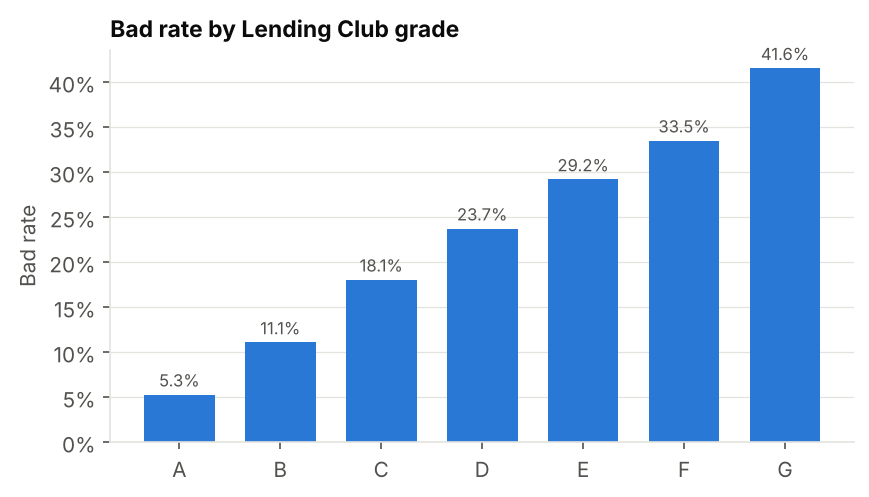

In [5]:
display(pd.read_csv(R + 'bad_rate_by_grade.csv')); display(Image(F + 'bad_rate_by_grade.png'))

## Missing values (candidate features)

In [6]:
pd.read_csv(R + 'missing_values.csv').query('missing_share > 0')

,Unnamed: 0,missing_share
0,mths_since_last_delinq,0.498357
1,mths_since_recent_inq,0.106109
2,emp_length_yrs,0.061478
3,bc_util,0.010533
4,percent_bc_gt_75,0.010515
5,bc_open_to_buy,0.009866
6,revol_util,0.000471
7,pct_tl_nvr_dlq,0.000209
8,avg_cur_bal,0.000016
